## RoT and TERP on CelebA faces

The image experiment of the [TERP paper](https://doi.org/10.1038/s41467-024-51970-x) (Mehdi & Tiwary 2024, Fig. 5),
redone with RoT next to TERP:

- **Data:** [CelebA](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html), 202,599 aligned celebrity faces with 40
  yes/no labels each (here from the `flwrlabs/celeba` mirror on the HuggingFace Hub; only the shards used are downloaded).
- **Black box:** a ViT-B/16 pretrained on ImageNet-21k (`google/vit-base-patch16-224-in21k`, as in the paper),
  fine-tuned here to predict **Eyeglasses** and **Male**. A 224×224 face is cut into 196 patches of 16×16 pixels.
- **TERP:** the paper's recipe. The 196 patches are the features; a patch is switched off by painting it with its
  own average colour; 5,000 random copies per face; TERP picks how many patches to keep (`j`) by itself.
- **RoT:** fitted on the black box's own answers, reading the black box's patch features (the 196 patch tokens
  that enter the ViT's last block, 768 numbers each). Its map is one number per patch, like TERP's.

Three ways to compare them, on the same test faces:

1. **TERP's grades** (U, S, ζ, as in notebook 08), on TERP's own copies of each face.
2. **Deleting patches from the black box's input**, most important first, and watching the black box's confidence
   fall. This uses only the black box, so it is fair to both explainers. A random order is the floor.
3. **How alike the two maps are** (rank correlation over the 196 patches).

In [1]:
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from ruleofthumb import fit_image

OUT = "experiment-celeba/out"
CACHE = os.environ.get("CELEBA_CACHE", "experiment-celeba/cache")   # decoded faces and black-box weights
ATTRS = ["Eyeglasses", "Male"]
SIZE, PATCH = 224, 16
GRID = SIZE // PATCH                       # 14 x 14 = 196 patches
N_TRAIN = 30000                            # faces used to fine-tune the black box
BB_EPOCHS, BB_BATCH, BB_LR = 2, 64, 2e-5
N_POOL_POS = 2000                          # RoT pool: this many faces with glasses + as many without
LAYER = -2                                 # patch tokens entering the ViT's last block
EPOCHS, BATCH, LR = 300, 2000, 0.05        # RoT: the image-experiment settings of notebook 07
N_POINTS = 30                              # test faces explained by TERP and RoT
N_SHOW = 6                                 # faces drawn per attribute
N_SAMPLES = 5000                           # TERP neighbourhood size
CUTOFF = 25                                # TERP stage 1 keeps this many patches
DELETE = [0, 1, 2, 3, 5, 10, 20, 40, 80]   # patches deleted in the black-box deletion test
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT, exist_ok=True)
os.makedirs(CACHE, exist_ok=True)
warnings.filterwarnings("ignore", message="low train agreement")
print("device:", DEVICE)

mkdir -p failed for path /nvme/.cache/matplotlib: [Errno 13] Permission denied: '/nvme/.cache'


Matplotlib created a temporary cache directory at /tmp/matplotlib-pibqd30i because there was an issue with the default path (/nvme/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


device: cuda


## The faces

Aligned CelebA faces are 178×218; each is cut to its middle 178×178 square and resized to 224×224. Decoded faces are
cached as `uint8` arrays under `CACHE`.

- **Black-box training set:** `N_TRAIN` random faces from the first 4 of the 19 shards of CelebA's `train` split (about 34k faces).
- **RoT pool:** faces from the `valid` and `test` splits, which the black box never sees. Only about 6.5% of
  CelebA wears glasses, so the pool takes `N_POOL_POS` faces with glasses and as many without. 80% of the pool fits
  RoT, 20% tests it.

In [2]:
import io

import pyarrow as pa
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
from PIL import Image

REPO, CONFIG = "flwrlabs/celeba", "img_align+identity+attr"
SHARDS = {"train": (4, 19), "valid": (3, 3), "test": (3, 3)}   # (shards used, shards in the split)


def table(split):
    used, total = SHARDS[split]
    return pa.concat_tables(
        pq.read_table(hf_hub_download(REPO, f"{CONFIG}/{split}-{i:05d}-of-{total:05d}.parquet", repo_type="dataset"))
        for i in range(used))


def decode(png):
    face = Image.open(io.BytesIO(png)).convert("RGB")
    top = (face.height - face.width) // 2
    face = face.crop((0, top, face.width, top + face.width)).resize((SIZE, SIZE), Image.BILINEAR)
    return np.asarray(face).transpose(2, 0, 1)


def cached(name, splits, pick):
    # Decoded faces (n, 3, 224, 224) uint8 and their CelebA labels (n, attrs) for the rows `pick(table)` chooses
    path = f"{CACHE}/{name}.npz"
    if not os.path.exists(path):
        t = pa.concat_tables(table(s) for s in splits)
        rows = pick(t)
        col = t.column("image")                       # take() would join the chunks: over 2 GiB of PNGs overflows
        starts = np.cumsum([0] + [len(c) for c in col.chunks])
        chunk = np.searchsorted(starts, rows, side="right") - 1
        images = np.stack([decode(col.chunks[k][int(r - starts[k])]["bytes"].as_py()) for k, r in zip(chunk, rows)])
        labels = np.stack([t.column(a).take(rows).to_numpy(zero_copy_only=False) for a in ATTRS], 1)
        np.savez(path, images=images, labels=labels.astype(np.int64))
    data = np.load(path)
    return data["images"], data["labels"]


def balanced(t):
    glasses = t.column("Eyeglasses").to_numpy(zero_copy_only=False).astype(bool)
    rng = np.random.RandomState(1)
    return rng.permutation(np.r_[rng.choice(np.flatnonzero(glasses), N_POOL_POS, replace=False),
                                 rng.choice(np.flatnonzero(~glasses), N_POOL_POS, replace=False)])


train_x, train_y = cached("train", ["train"], lambda t: np.random.RandomState(0).permutation(len(t))[:N_TRAIN])
pool_x, pool_y = cached("pool", ["valid", "test"], balanced)
rot_train = np.arange(int(0.8 * len(pool_x)))
rot_test = np.arange(len(rot_train), len(pool_x))
print(f"black-box training faces {train_x.shape} | RoT pool {pool_x.shape} (fit {len(rot_train)}, test {len(rot_test)})")
print("share with the attribute: train", dict(zip(ATTRS, train_y.mean(0).round(3))),
      "| pool", dict(zip(ATTRS, pool_y.mean(0).round(3))))

/home/azureuser/aru_nb07/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


black-box training faces (30000, 3, 224, 224) | RoT pool (4000, 3, 224, 224) (fit 3200, test 800)
share with the attribute: train {'Eyeglasses': np.float64(0.057), 'Male': np.float64(0.389)} | pool {'Eyeglasses': np.float64(0.5), 'Male': np.float64(0.59)}


## The black box: a ViT fine-tuned on CelebA

One ViT with one yes/no output per attribute. Its weights are cached; delete `CACHE/vit_celeba.pt` to retrain.

In [3]:
from transformers import ViTModel

VIT = "google/vit-base-patch16-224-in21k"


class BlackBox(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTModel.from_pretrained(VIT, add_pooling_layer=False)
        self.head = torch.nn.Linear(self.vit.config.hidden_size, len(ATTRS))

    def forward(self, pixels, features=False):
        out = self.vit(pixel_values=pixels, output_hidden_states=features)
        logits = self.head(out.last_hidden_state[:, 0])            # the [CLS] token, as in ViTForImageClassification
        if not features:
            return logits
        patches = out.hidden_states[LAYER][:, 1:]                   # (n, 196, 768), [CLS] dropped
        return logits, patches.transpose(1, 2).reshape(len(pixels), -1, GRID, GRID)


def to_pixels(u8):
    # The ViT's own preprocessing: [0, 1] scaled to [-1, 1]
    return (torch.as_tensor(u8, device=DEVICE).float() / 255 - 0.5) / 0.5


black_box = BlackBox().to(DEVICE)
BB_PATH = f"{CACHE}/vit_celeba.pt"
if os.path.exists(BB_PATH):
    black_box.load_state_dict(torch.load(BB_PATH, map_location=DEVICE, weights_only=True))
else:
    torch.manual_seed(0)
    opt = torch.optim.AdamW(black_box.parameters(), lr=BB_LR, weight_decay=0.01)
    black_box.train()
    for epoch in range(BB_EPOCHS):
        perm, total = np.random.RandomState(epoch).permutation(len(train_x)), 0.0
        for s in range(0, len(perm), BB_BATCH):
            rows = perm[s : s + BB_BATCH]
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
                logits = black_box(to_pixels(train_x[rows]))
            loss = torch.nn.functional.binary_cross_entropy_with_logits(
                logits.float(), torch.as_tensor(train_y[rows], device=DEVICE).float())
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(rows)
        print(f"epoch {epoch}: loss {total / len(perm):.4f}", flush=True)
    torch.save(black_box.state_dict(), BB_PATH)
black_box.eval()


@torch.no_grad()
def run(u8_or_pixels, features=False, batch=250):
    # Black-box probabilities (n, attrs) and, with features=True, the patch features (n, 768, 14, 14) in float16.
    probs, feats = [], []
    for s in range(0, len(u8_or_pixels), batch):
        chunk = u8_or_pixels[s : s + batch]
        pixels = chunk if torch.is_tensor(chunk) and chunk.is_floating_point() else to_pixels(chunk)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
            out = black_box(pixels, features)
        logits, f = out if features else (out, None)
        probs.append(torch.sigmoid(logits.float()).cpu())
        if features:
            feats.append(f.half().cpu())
    return (torch.cat(probs).numpy(), torch.cat(feats)) if features else torch.cat(probs).numpy()


pool_prob, pool_feat = run(pool_x, features=True)
bb_label = (pool_prob > 0.5).astype(np.int64)                     # what RoT learns: the black box's answers
for a, attr in enumerate(ATTRS):
    print(f"{attr}: black-box accuracy on the pool {(bb_label[:, a] == pool_y[:, a]).mean():.3f}, "
          f"says yes for {bb_label[:, a].mean():.3f}")
print("patch features", tuple(pool_feat.shape))

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 5619.16it/s]


[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.weight | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 0: loss 0.1410


epoch 1: loss 0.0519


Eyeglasses: black-box accuracy on the pool 0.982, says yes for 0.485
Male: black-box accuracy on the pool 0.959, says yes for 0.555
patch features (4000, 768, 14, 14)


## RoT on the black box's patch features

One binary RoT per attribute (`fit_image`, package defaults except the notebook-07 training settings). RoT's patch
map for class `c` is `Σ_channels a_c · (x + b_c)` per patch. With two classes, what moves the answer is the
difference between the two classes' maps, so every RoT map below is `map(explained class) − map(other class)`:
positive patches push toward the black box's answer.

In [4]:
def rot_patches(model, feats, batch=250):
    # Per-patch contributions of both classes, (n, 2, 196), in float32 on the CPU
    out = []
    with torch.no_grad():
        for s in range(0, len(feats), batch):
            out.append(model.importance(feats[s : s + batch].float()).sum(2).flatten(2).cpu())
    return torch.cat(out).numpy()


rots = {}
for a, attr in enumerate(ATTRS):
    exp = fit_image(bb_label[rot_train, a], pool_feat[rot_train].float().numpy(), epochs=EPOCHS, batch_size=BATCH,
                    learning_rate=LR, seed=0, device=DEVICE)
    test_pred = exp.predict(pool_feat[rot_test].float().numpy()).cpu().numpy()
    rots[attr] = exp.model
    print(f"{attr}: RoT agreement with the black box, train {exp.train_agreement_:.3f}, "
          f"test {(test_pred == bb_label[rot_test, a]).mean():.3f}", flush=True)

Eyeglasses: RoT agreement with the black box, train 1.000, test 0.999


Male: RoT agreement with the black box, train 1.000, test 0.996


## TERP for patches

The functions of notebook 08, with patches in place of pixels. A switched-off patch takes its own average colour
(the paper's choice); TERP's regression inputs are the 196 on/off switches.

In [5]:
def neighbourhood(face, rng, n=N_SAMPLES):
    # n copies of one face (3, 224, 224) uint8, each patch kept or painted with its mean colour with probability
    # 0.5; row 0 is the face itself. Returns the copies as ViT pixels (on the GPU) and the (n, 196) on/off switches.
    kept = rng.randint(0, 2, size=(n, GRID, GRID)).astype(np.float32)
    kept[0] = 1.0
    return paint(face, kept), kept.reshape(n, -1)


def paint(face, kept):
    # Copies of `face` with the patches where kept == 0 painted with their average colour (ViT pixels, GPU)
    x0 = torch.as_tensor(face, device=DEVICE).float()
    means = x0.reshape(3, GRID, PATCH, GRID, PATCH).mean((2, 4))
    up = lambda t: t.repeat_interleave(PATCH, -1).repeat_interleave(PATCH, -2)
    k = up(torch.as_tensor(kept, device=DEVICE))[:, None]
    return ((k * x0 + (1 - k) * up(means)) / 255 - 0.5) / 0.5


def similarity(kept):
    # TERP's image similarity: cosine distance to the unchanged face, kernel width 0.25
    norms = np.linalg.norm(kept, axis=1) * np.linalg.norm(kept[0])
    cos_dist = 1.0 - (kept @ kept[0]) / np.where(norms > 0, norms, 1.0)
    return np.sqrt(np.exp(-(cos_dist**2) / 0.25**2))


def entropy(weights):
    a = np.abs(weights) / np.abs(weights).sum()
    a = a[a > 0]
    return float(-(a * np.log(a)).sum() / np.log(len(weights)))


def unfaithfulness(target, pred, w):
    tm, pm = np.average(target, weights=w), np.average(pred, weights=w)
    cov = np.average((target - tm) * (pred - pm), weights=w)
    var = np.average((target - tm) ** 2, weights=w) * np.average((pred - pm) ** 2, weights=w)
    return 1.0 - abs(cov) / np.sqrt(var) if var > 0 else 1.0


def ridge(x, y, w, alpha=1.0):
    xm, ym = np.average(x, axis=0, weights=w), np.average(y, weights=w)
    xc = x - xm
    coef = np.linalg.solve(xc.T @ (w[:, None] * xc) + alpha * np.eye(x.shape[1]), xc.T @ (w * (y - ym)))
    return coef, ym - xm @ coef


def native_terp(t, target, w, cutoff=CUTOFF):
    # Stage 1: ridge on all patches, keep the top `cutoff`; stage 2: greedy forward selection.
    # Returns U, S and the weights as a full 196-patch map per number of patches, and the stage-1 dense weights.
    dense = ridge(t, target, w)[0]
    keep = np.argsort(-np.abs(dense))[:cutoff]
    data, k_max = t[:, keep], len(keep)
    chosen, us, ss, maps = [], [], [], []
    for _ in range(k_max):
        best = None
        for f in (f for f in range(k_max) if f not in chosen):
            cols = chosen + [f]
            c, b = ridge(data[:, cols], target, w)
            u = unfaithfulness(target, data[:, cols] @ c + b, w)
            if best is None or u < best[0]:
                best = (u, f, c)
        u, f, c = best
        chosen.append(f)
        weights = np.zeros(k_max)
        weights[chosen] = c
        full = np.zeros(t.shape[1])
        full[keep] = weights
        us.append(u)
        ss.append(entropy(weights))
        maps.append(full)
    return np.array(us), np.array(ss), np.array(maps), dense


def pick_j(us, ss):
    du, ds = np.diff(us), np.diff(ss)
    theta = np.where((du < 0) & (ds > 1e-9), -du / np.where(ds > 1e-9, ds, 1.0), 0.0)
    r = int(np.argmin(np.diff(theta))) if len(theta) > 1 else 0
    return r + 1, float(theta[r : r + 2].mean())


def zeta_at(us, ss, theta):
    z = us + theta * ss
    return float(z.min()), int(z.argmin()) + 1


def rot_curve(imp, imp0, g, c, target, w, k_max, order=None):
    # U_j and S_j for RoT keeping its top-j patches for this face (or a given order); hidden patches contribute 0.
    # imp: RoT's (n, 2, 196) contributions on the TERP copies, imp0: on the face itself.
    d0 = imp0[c] - imp0[1 - c]
    order = (np.argsort(-np.abs(d0)) if order is None else order)[:k_max]
    scores = g[None, :, None] + np.cumsum(imp[:, :, order], axis=2)           # (n, 2, k_max)
    scores = scores - scores.max(1, keepdims=True)
    prob = np.exp(scores[:, c]) / np.exp(scores).sum(1)
    us = np.array([unfaithfulness(target, prob[:, j], w) for j in range(k_max)])
    w0 = np.abs(d0[order])
    ss = np.array([entropy(np.r_[w0[: j + 1], np.zeros(k_max - j - 1)]) for j in range(k_max)])
    return us, ss


def ranks(v):
    return np.argsort(np.argsort(v)).astype(float)


def spearman(u, v):
    return float(np.corrcoef(ranks(u), ranks(v))[0, 1])

## Explaining the test faces

`N_POINTS` test faces, half of them with glasses according to the black box. For every face and attribute, the
explained class `c` is the black box's answer, and `g` is the black box's probability of it.

- **TERP** fits on its 5,000 copies of the face.
- **RoT** is graded on the same copies: `F_j` is RoT's probability of `c` with only its top-`j` patches kept.
- **Deletion test:** the top-`k` patches of each ranking are painted out of the real face and the black box is
  asked again. Rankings: RoT's map, TERP's dense stage-1 weights (TERP's chosen model only ranks `j` patches), and
  a random order. Results are cached in `OUT/results.json`; delete it to recompute.

In [6]:
def deletion(face, ranking, a, c):
    # The black box's probability of class c after painting out the top-k patches of `ranking`, for k in DELETE
    kept = np.ones((len(DELETE), GRID * GRID), dtype=np.float32)
    for i, k in enumerate(DELETE):
        kept[i, ranking[:k]] = 0.0
    p = run(paint(face, kept.reshape(-1, GRID, GRID)))[:, a]
    return (p if c == 1 else 1 - p).tolist()


RESULTS = f"{OUT}/results.json"
if os.path.exists(RESULTS):
    with open(RESULTS) as fh:
        results = json.load(fh)
else:
    test_glasses = bb_label[rot_test, 0]
    faces = np.r_[rot_test[test_glasses == 1][: N_POINTS // 2], rot_test[test_glasses == 0][: N_POINTS - N_POINTS // 2]]
    results = {attr: [] for attr in ATTRS}
    for i, idx in enumerate(faces):
        face = pool_x[idx]
        pixels, kept = neighbourhood(face, np.random.RandomState(1000 + i))
        prob, feats = run(pixels, features=True)
        w = similarity(kept)
        for a, attr in enumerate(ATTRS):
            model = rots[attr]
            g = model.g.detach().cpu().numpy()
            imp = rot_patches(model, feats)
            c = int(prob[0, a] > 0.5)
            target = prob[:, a] if c == 1 else 1 - prob[:, a]
            us, ss, maps, dense = native_terp(kept, target, w)
            m, theta = pick_j(us, ss)
            zeta, _ = zeta_at(us, ss, theta)
            row = {"idx": int(idx), "c": c, "p": float(target[0]),
                   "terp": {"U": us[m], "S": ss[m], "zeta": zeta, "j": m + 1, "theta": theta, "map": maps[m].tolist()}}
            d0 = imp[0, c] - imp[0, 1 - c]
            row["rot_map"] = d0.tolist()
            for kind in ("rot", "random"):
                order = np.random.RandomState(i).permutation(GRID * GRID) if kind == "random" else None
                r_us, r_ss = rot_curve(imp, imp[0], g, c, target, w, len(us), order)
                rm, _ = pick_j(r_us, r_ss)
                row[kind] = {"U": r_us[rm], "S": r_ss[rm], "zeta": zeta_at(r_us, r_ss, theta)[0], "j": rm + 1}
            row["delete"] = {"rot": deletion(face, np.argsort(-d0), a, c),
                             "terp": deletion(face, np.argsort(-dense), a, c),
                             "random": deletion(face, np.random.RandomState(i).permutation(GRID * GRID), a, c)}
            row["spearman"] = spearman(dense, d0)
            results[attr].append(row)
        print(f"face {i + 1}/{len(faces)}", flush=True)
    with open(RESULTS, "w") as fh:
        json.dump(results, fh, default=float)

face 1/30


face 2/30


face 3/30


face 4/30


face 5/30


face 6/30


... (20 outputs left out)

face 27/30


face 28/30


face 29/30


face 30/30


## What each explainer looks at

For each attribute, one row per face: the face, TERP's chosen patches, and RoT's full patch map. Red pushes toward
the black box's answer, blue against it; each map is scaled on its own.

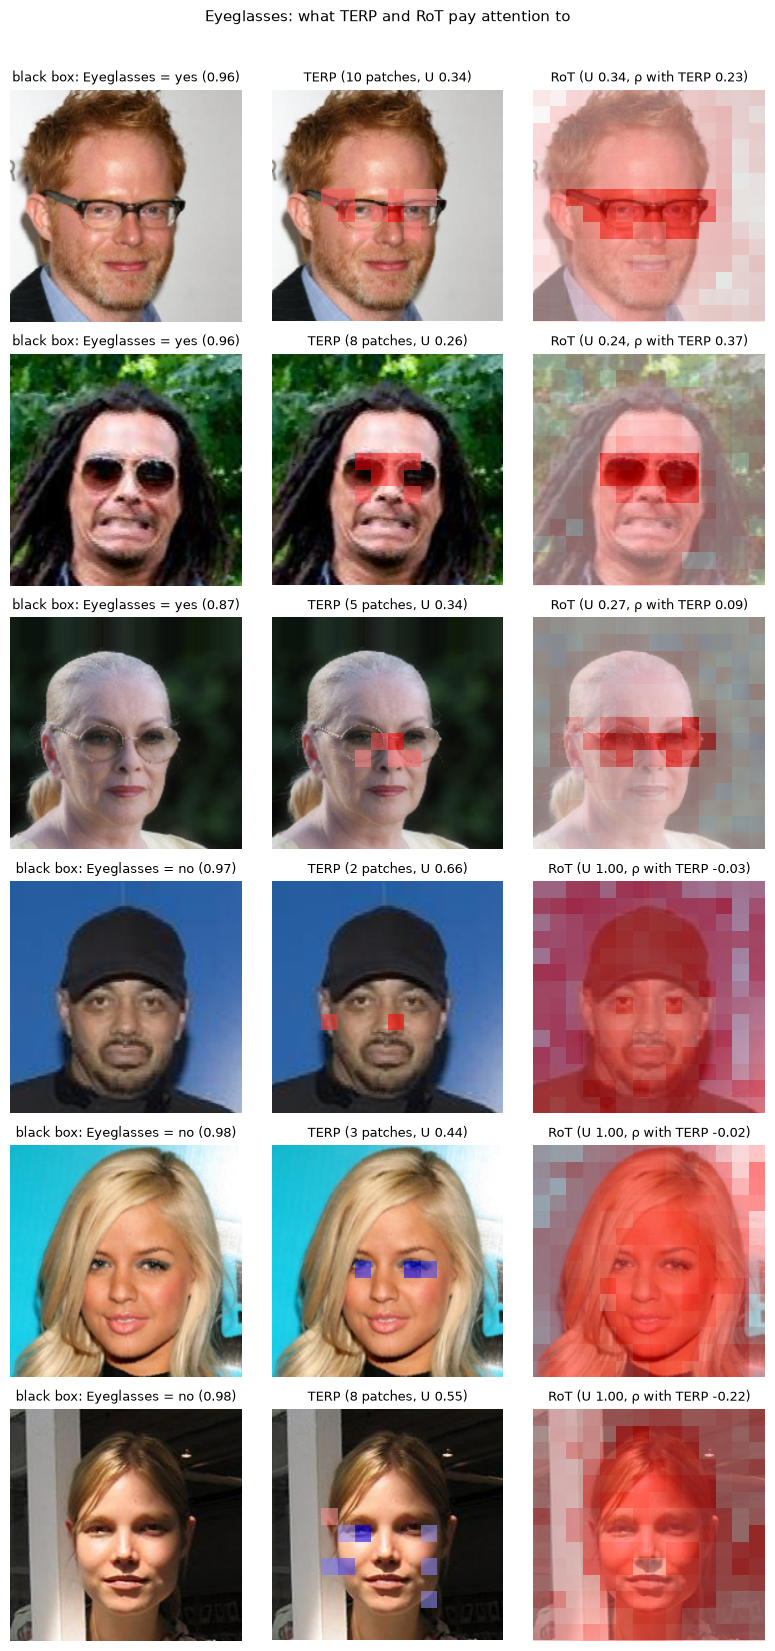

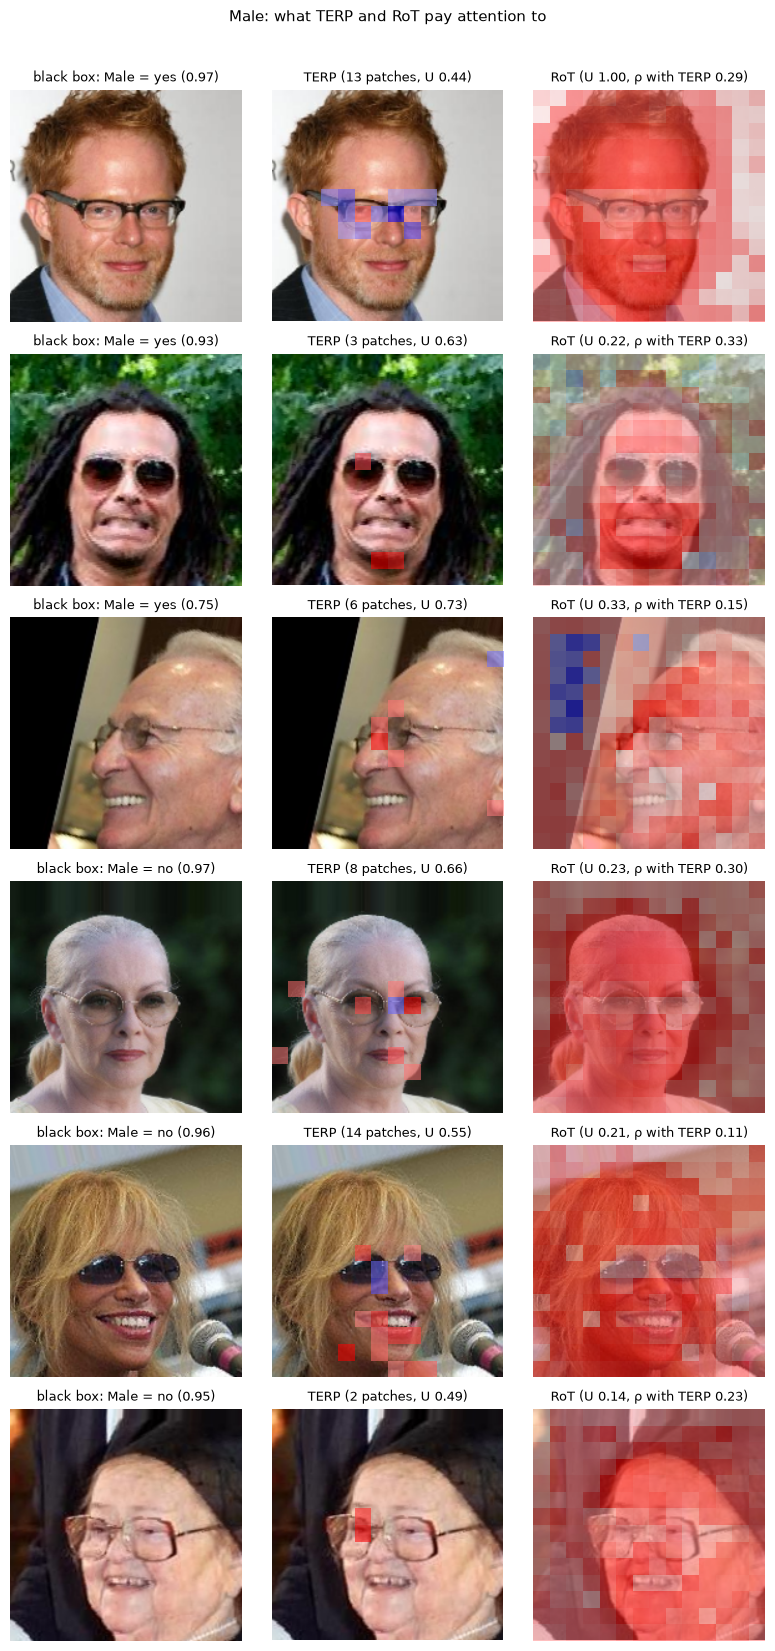

In [7]:
def overlay(ax, face, heat, title):
    heat = np.asarray(heat).reshape(GRID, GRID)
    m = np.abs(heat).max() or 1.0
    heat = np.ma.masked_equal(heat, 0.0)            # patches outside the explanation stay unpainted
    ax.imshow(face.transpose(1, 2, 0))
    ax.imshow(heat, cmap="bwr", vmin=-m, vmax=m, alpha=0.55, extent=(0, SIZE, SIZE, 0), interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")


for attr in ATTRS:
    rows = results[attr]
    picks = [r for r in rows if r["c"] == 1][: N_SHOW // 2] + [r for r in rows if r["c"] == 0][: N_SHOW - N_SHOW // 2]
    fig, axes = plt.subplots(len(picks), 3, figsize=(8, 2.8 * len(picks)))
    for ax_row, r in zip(axes, picks):
        face = pool_x[r["idx"]]
        ax_row[0].imshow(face.transpose(1, 2, 0))
        ax_row[0].set_title(f"black box: {attr} = {'yes' if r['c'] else 'no'} ({r['p']:.2f})", fontsize=9)
        ax_row[0].axis("off")
        overlay(ax_row[1], face, r["terp"]["map"], f"TERP ({r['terp']['j']} patches, U {r['terp']['U']:.2f})")
        overlay(ax_row[2], face, r["rot_map"], f"RoT (U {r['rot']['U']:.2f}, ρ with TERP {r['spearman']:.2f})")
    fig.suptitle(f"{attr}: what TERP and RoT pay attention to", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(f"{OUT}/saliency_{attr.lower()}.png", dpi=110)
    plt.show()

## Scores

- **U, S, ζ, j:** TERP's grades at each explainer's chosen `j` (ζ at TERP's own θ, as in notebook 08; lower is
  better).
- **Deletion AUC:** the black box's mean confidence in its answer over the deletion steps (lower = the ranking found
  the patches the black box needs).
- **ρ:** Spearman correlation between TERP's dense weights and RoT's map over the 196 patches.

| attribute | explainer | U | S | ζ | j | deletion AUC |
|---|---|---|---|---|---|---|
| Eyeglasses | TERP | 0.396 ± 0.127 | 0.511 ± 0.202 | 0.596 ± 0.109 | 6.667 ± 4.445 | 0.688 ± 0.286 |
| Eyeglasses | RoT | 0.619 ± 0.350 | 0.509 ± 0.312 | 0.647 ± 0.326 | 8.467 ± 7.658 | 0.726 ± 0.270 |
| Eyeglasses | random order | 0.542 ± 0.430 | 0.421 ± 0.280 | 0.576 ± 0.402 | 7.100 ± 7.240 | 0.938 ± 0.053 |
| Eyeglasses | ρ(TERP, RoT) | 0.093 ± 0.196 | | | | |
| Male | TERP | 0.599 ± 0.115 | 0.488 ± 0.199 | 0.741 ± 0.100 | 6.067 ± 4.024 | 0.758 ± 0.178 |
| Male | RoT | 0.472 ± 0.383 | 0.459 ± 0.288 | 0.513 ± 0.358 | 6.967 ± 7.012 | 0.911 ± 0.117 |
| Male | random order | 0.450 ± 0.366 | 0.555 ± 0.304 | 0.460 ± 0.342 | 9.767 ± 8.273 | 0.960 ± 0.035 |
| Male | ρ(TERP, RoT) | 0.201 ± 0.092 | | | | |

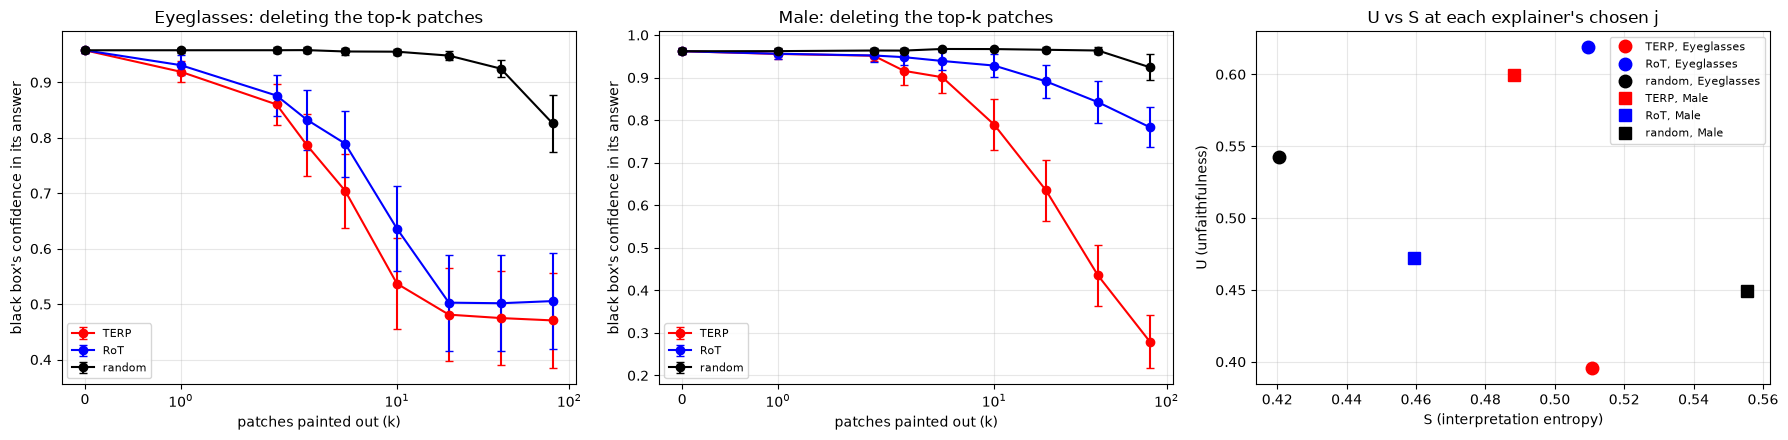

In [8]:
def mean_sd(values):
    values = np.asarray(values, float)
    return f"{values.mean():.3f} ± {values.std():.3f}"


lines = ["| attribute | explainer | U | S | ζ | j | deletion AUC |", "|---|---|---|---|---|---|---|"]
for attr in ATTRS:
    rows = results[attr]
    for kind, name in (("terp", "TERP"), ("rot", "RoT"), ("random", "random order")):
        grades = " | ".join(mean_sd([r[kind][k] for r in rows]) for k in ("U", "S", "zeta", "j"))
        lines.append(f"| {attr} | {name} | {grades} | {mean_sd([np.mean(r['delete'][kind]) for r in rows])} |")
    lines.append(f"| {attr} | ρ(TERP, RoT) | {mean_sd([r['spearman'] for r in rows])} | | | | |")
display(Markdown("\n".join(lines)))

fig, axes = plt.subplots(1, len(ATTRS) + 1, figsize=(6 * (len(ATTRS) + 1), 4.5))
styles = {"terp": ("TERP", "r"), "rot": ("RoT", "b"), "random": ("random", "k")}
for ax, attr in zip(axes, ATTRS):
    rows = results[attr]
    for kind, (name, colour) in styles.items():
        curves = np.array([r["delete"][kind] for r in rows])
        ax.errorbar(DELETE, curves.mean(0), yerr=curves.std(0) / np.sqrt(len(curves)), fmt="o-", color=colour,
                    label=name, capsize=3)
    ax.set(title=f"{attr}: deleting the top-k patches", xlabel="patches painted out (k)",
           ylabel="black box's confidence in its answer", xscale="symlog")
    ax.legend(fontsize=8)
ax = axes[-1]
for attr, marker in zip(ATTRS, "os"):
    rows = results[attr]
    for kind, (name, colour) in styles.items():
        ax.plot(np.mean([r[kind]["S"] for r in rows]), np.mean([r[kind]["U"] for r in rows]), marker, color=colour,
                ms=9, label=f"{name}, {attr}")
ax.set(title="U vs S at each explainer's chosen j", xlabel="S (interpretation entropy)", ylabel="U (unfaithfulness)")
ax.legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f"{OUT}/scores.png", dpi=110)
plt.show()